# จูนโมเดลที่เหลือ (DenseNet121, EfficientNet-B0)

notebook หลักจูนเฉพาะ Top 1 (ResNet50) ส่วน ConvNeXt-Tiny ถูกจูนไว้ในรอบรันก่อนหน้า
notebook นี้ทำขั้นตอนเดียวกันกับอีก 2 โมเดล เพื่อให้มีกราฟก่อน/หลังจูนครบทุกโมเดล:
ใช้รอบ augmentation ที่ดีที่สุดของโมเดลนั้นจากรอบคัดเลือก → ก่อนจูน 3 seed → Optuna 15 trial → หลังจูน 3 seed
ผลเขียนที่ `results/others/` (ไม่ทับผลของ notebook หลัก)

In [1]:
# ===== Config: แก้เฉพาะ cell นี้ =====
from pathlib import Path

PROJECT_DIR = Path.cwd()                 # โฟลเดอร์ที่มี notebook นี้ (ให้เปิด notebook จากโฟลเดอร์โปรเจค)
DATA_DIR    = PROJECT_DIR / "dataset"    # dataset/<source>/<Class>/...
OUTPUT_DIR  = PROJECT_DIR                # ที่เก็บผลลัพธ์ทั้งหมด

SOURCES = ["iBUG", "TextileClass7"]
# TextileClass7: Roboflow ทำ augmentation ไว้ 3 เวอร์ชันต่อรูป ชื่อไฟล์เป็น "<ต้นฉบับ>_jpg.rf.<hash>.jpg"
# จึงตัด "_jpg.rf.<hash>" ออกเพื่อให้ทุกเวอร์ชันของรูปเดียวกันเป็นชิ้นผ้าเดียวกัน
GROUP_REGEX = {"iBUG": None, "TextileClass7": r"_(jpe?g|png)\.rf\.[0-9a-f]+$"}
FABRIC_GROUPS_CSV = PROJECT_DIR / "data_audit" / "fabric_groups.csv"  # รูปหลายรูปของผ้าชิ้นเดียวกัน
EXCLUDE_CSV       = PROJECT_DIR / "data_audit" / "exclude.csv"        # รูปที่ label ขัดแย้ง
EVAL_ONE_PER_PIECE = True                # Val/Test ใช้ 1 รูปต่อชิ้นผ้า

SEED     = 42
IMG_SIZE = 224
MIN_SIDE = 64
SPLIT    = (0.70, 0.15, 0.15)            # Train / Val / Test
N_JOBS   = -1                            # จำนวน process ตอนสแกนรูป

# ===== โมเดลและการเทรน =====
MODEL_KEYS  = ["resnet50", "densenet121", "efficientnet_b0", "convnext_tiny"]   # torchvision
ROUNDS = ["none", "v1", "v2", "texture"] # รอบตามสไลด์ (none/v1/v2) + texture = augmentation ที่รักษาพื้นผิวผ้า
UNSEEN_DIR = PROJECT_DIR / "unseen_data" # รูปจากอินเทอร์เน็ต (TextileNet) ใช้วัดผลอย่างเดียว
SEEDS       = (42, 7, 2024)              # seed ของผล "ก่อนจูน" และ "หลังจูน"
MAX_EPOCHS  = 30                         # epoch สูงสุดของเฟส fine-tune
PATIENCE    = 7                          # early stopping บน Val Macro-F1
BATCH_SIZE  = 32                         # GPU out-of-memory -> ลดเป็น 16 ให้อัตโนมัติ
NUM_WORKERS = 4
GPU_TEMP_PAUSE  = None                   # None = ไม่พักอัตโนมัติ (ผู้ใช้ดูอุณหภูมิและสั่งหยุดเอง); ใส่ตัวเลข เช่น 60 เพื่อพักเมื่อถึง °C นี้
GPU_TEMP_RESUME = 50                     # ถ้าเปิดการพักอัตโนมัติ: พักจนเย็นลงถึงกี่ °C แล้วจึงเทรนต่อ
N_TRIALS     = 15                        # จำนวน trial ของ Optuna
TRIAL_EPOCHS = 12                        # epoch ของเฟส fine-tune ใน 1 trial (สั้นกว่าเทรนจริงเพื่อประหยัดเวลา)

F1_TARGET      = 0.85                    # เป้า Test Macro-F1 ตาม PRD (ไม่ถึง -> ต้องทำขั้นสำรอง)
CONF_THRESHOLD = 0.60                    # ความมั่นใจต่ำกว่านี้ แอปจะเตือนให้คนตรวจซ้ำ
SKIP_TRAINING_IF_EXISTS = True           # มีผลของ run เดียวกันอยู่แล้ว -> โหลดมาใช้แทนการเทรนใหม่
LAUNCH_APP = True
APP_PORT   = 8501

SMOKE = False                            # True = ทดสอบเร็ว (ผลไม่ใช้จริง เขียนแยกที่ *_smoke/)
SMOKE_PER_CLASS = 48
if SMOKE:
    MAX_EPOCHS, TRIAL_EPOCHS, N_TRIALS, SEEDS, PATIENCE = 2, 2, 2, (42, 7), 2

# โฟลเดอร์ผลลัพธ์ (ไม่ต้องแก้)
SPLIT_DIR   = OUTPUT_DIR / "results"                               # manifest.csv, split.csv (ใช้ร่วมกันเสมอ)
RESULTS_DIR = OUTPUT_DIR / "results" / ("_smoke" if SMOKE else "")
MODELS_DIR  = OUTPUT_DIR / "models" / ("_smoke" if SMOKE else "")
RUNS_DIR    = MODELS_DIR / "runs"                                  # <run_id>.pth
HIST_DIR    = RESULTS_DIR / "histories"                            # <run_id>.json
for d in (SPLIT_DIR, RESULTS_DIR, MODELS_DIR, RUNS_DIR, HIST_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [2]:
import sys, os, json, time, random, re, hashlib, warnings, platform, importlib, io, math, shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from joblib import Parallel, delayed
import sklearn, PIL
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import torch, torchvision, optuna
import torch.nn.functional as F
from IPython.display import display, HTML

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))  # ให้ process ลูกของ DataLoader import fabric_lib ได้
import fabric_lib as fl
importlib.reload(fl)

CLASSES = fl.CLASSES
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.benchmark = True


def evaluate(y_true, proba):
    """วัดผลจาก probability (n, 4) -> dict ของตัวชี้วัด (คลาสที่ไม่มีตัวอย่างในชุดนั้นได้ NaN)"""
    y_pred = np.asarray(proba).argmax(1)
    p, r, f, support = precision_recall_fscore_support(y_true, y_pred, labels=range(len(CLASSES)), zero_division=0)
    has = support > 0
    p, r, f = (np.where(has, v, np.nan) for v in (p, r, f))
    m = {"accuracy": accuracy_score(y_true, y_pred), "macro_precision": np.nanmean(p),
         "macro_recall": np.nanmean(r), "macro_f1": np.nanmean(f), "min_recall": np.nanmin(r)}
    for i, c in enumerate(CLASSES):
        m[f"precision_{c}"], m[f"recall_{c}"], m[f"f1_{c}"] = p[i], r[i], f[i]
    return {k: float(v) for k, v in m.items()}


def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / name, dpi=150, bbox_inches="tight")


seed_everything()
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3,
                     "font.family": ["Leelawadee UI", "Tahoma", "DejaVu Sans"]})  # แสดงภาษาไทยในกราฟได้
plt.rcParams["figure.dpi"] = 100
warnings.filterwarnings("ignore", message=".*least populated class.*")
optuna.logging.set_verbosity(optuna.logging.WARNING)

versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "torch": torch.__version__, "torchvision": torchvision.__version__,
            "optuna": optuna.__version__}
display(pd.Series(versions, name="version").to_frame())

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} ({props.total_memory / 2**30:.1f} GB), CUDA {torch.version.cuda}")
else:
    print("ไม่พบ GPU ที่ใช้ CUDA ได้: จะเทรนบน CPU ซึ่งช้ามาก ตรวจการติดตั้ง PyTorch แบบ CUDA ใน README.md")

,version
python,3.14.2
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
torch,2.14.0+cu126
torchvision,0.29.0+cu126
optuna,5.0.0


GPU: NVIDIA GeForce RTX 4050 Laptop GPU (6.0 GB), CUDA 12.6


In [3]:
def piece_id(source, cls, rel):
    """ID ชิ้นผ้าสำหรับ group split: โฟลเดอร์ย่อย หรือชื่อไฟล์ที่ตัดส่วนท้ายด้วย GROUP_REGEX"""
    if len(rel.parts) > 1:
        piece = "/".join(rel.parts[:-1])
    else:
        rx = GROUP_REGEX.get(source)
        piece = re.sub(rx, "", rel.stem) if rx else rel.stem
    return f"{source}/{cls}/{piece}"


rows, missing = [], []
for source in SOURCES:
    src_dir = DATA_DIR / source
    if not src_dir.is_dir():
        missing.append(src_dir)
        continue
    class_dirs = {d.name.lower(): d for d in src_dir.iterdir() if d.is_dir()}
    for cls in CLASSES:
        cdir = class_dirs.get(cls.lower())
        if cdir is None:
            missing.append(src_dir / cls)
            continue
        for p in sorted(cdir.rglob("*")):
            if p.is_file() and p.suffix.lower() in fl.IMG_EXTS:
                rows.append({"path": p.relative_to(DATA_DIR).as_posix(), "class": cls, "source": source,
                             "sample_id": piece_id(source, cls, p.relative_to(cdir))})
if missing:
    print("ไม่พบโฟลเดอร์:", *missing, sep="\n  ")
if not rows:
    raise FileNotFoundError(f"ไม่พบรูปใน {DATA_DIR} ดูโครงสร้างโฟลเดอร์ที่ต้องการใน cell Config")
manifest = pd.DataFrame(rows)
print(f"พบ {len(manifest):,} รูป")

if FABRIC_GROUPS_CSV.exists():
    fabric_of = pd.read_csv(FABRIC_GROUPS_CSV).set_index("photo_group")["fabric_id"]
    before = manifest["sample_id"].nunique()
    manifest["sample_id"] = manifest["sample_id"].map(fabric_of).fillna(manifest["sample_id"])
    print(f"รวมรูปของผ้าชิ้นเดียวกันตาม {FABRIC_GROUPS_CSV.name}: {before:,} -> {manifest['sample_id'].nunique():,} ชิ้น")

พบ 7,043 รูป
รวมรูปของผ้าชิ้นเดียวกันตาม fabric_groups.csv: 2,334 -> 2,209 ชิ้น


In [4]:
MANIFEST_PATH = SPLIT_DIR / "manifest.csv"
SCAN_COLS = ["md5", "width", "height", "ok", "error"]


def scan_image(path):
    """อ่านไฟล์ทั้งไฟล์: md5 ของไฟล์ + ขนาด + ถอดรหัสภาพได้หรือไม่"""
    data = Path(path).read_bytes()
    md5 = hashlib.md5(data).hexdigest()
    try:
        with Image.open(io.BytesIO(data)) as im:
            im.load()
            w, h = im.size
        return md5, w, h, True, ""
    except Exception as e:
        return md5, 0, 0, False, type(e).__name__


scanned = False
if MANIFEST_PATH.exists():
    old = pd.read_csv(MANIFEST_PATH, keep_default_na=False)
    if set(SCAN_COLS) <= set(old.columns) and set(old.path) == set(manifest.path):
        manifest = manifest.merge(old[["path"] + SCAN_COLS], on="path")
        manifest["ok"] = manifest["ok"].astype(str).eq("True")
        scanned = True
        print("ใช้ผลสแกนเดิมจาก", MANIFEST_PATH.name)
if not scanned:
    res = Parallel(n_jobs=N_JOBS, batch_size=32)(
        delayed(scan_image)(DATA_DIR / p) for p in tqdm(manifest.path, desc="scan images"))
    manifest[SCAN_COLS] = pd.DataFrame(res, columns=SCAN_COLS)
    manifest.to_csv(MANIFEST_PATH, index=False)
    print("บันทึก", MANIFEST_PATH)
display(manifest.head())

ใช้ผลสแกนเดิมจาก manifest.csv


,path,class,source,sample_id,md5,width,height,ok,error
0,iBUG/Cotton/10/im_1.png,Cotton,iBUG,iBUG/Cotton/10,188dfefb5a2e2c9843275f35deac8b5c,400,400,True,
1,iBUG/Cotton/10/im_2.png,Cotton,iBUG,iBUG/Cotton/10,cf948992ed09edbe9762ebe7cee0596c,400,400,True,
2,iBUG/Cotton/10/im_3.png,Cotton,iBUG,iBUG/Cotton/10,4a4efe774a50d93590dd24e6a41c220f,400,400,True,
3,iBUG/Cotton/10/im_4.png,Cotton,iBUG,iBUG/Cotton/10,80111bac6275d68de9e3d3cc9b0476ca,400,400,True,
4,iBUG/Cotton/100/im_1.png,Cotton,iBUG,iBUG/Cotton/100,92b828ca059bc476cac9319f19109af0,400,400,True,


In [5]:
df = manifest.copy()
n0 = len(df)
bad = ~df["ok"]
small = df["ok"] & (np.minimum(df.width, df.height) < MIN_SIDE)
df = df[~bad & ~small]
n_cls_per_md5 = df.groupby("md5")["class"].nunique()
conflict = df["md5"].isin(n_cls_per_md5[n_cls_per_md5 > 1].index)
df = df[~conflict]
dup = df.duplicated("md5", keep="first")
df = df[~dup]
excluded = pd.Series(False, index=df.index)
if EXCLUDE_CSV.exists():
    exclude_groups = set(pd.read_csv(EXCLUDE_CSV)["photo_group"])
    photo_group = df["source"] + "/" + df["class"] + "/" + df["path"].map(
        lambda p: re.sub(GROUP_REGEX.get(p.split("/")[0]) or r"$^", "", Path(p).stem))
    excluded = photo_group.isin(exclude_groups)
    df = df[~excluded]
df = df.reset_index(drop=True)

display(pd.DataFrame({"count": {
    "ภาพทั้งหมด": n0, "เปิดไม่ได้ (เสีย)": int(bad.sum()), f"เล็กกว่า {MIN_SIDE}px": int(small.sum()),
    "ซ้ำแต่คนละคลาส (ลบทั้งหมด)": int(conflict.sum()), "ซ้ำในคลาสเดียวกัน (เก็บไว้ 1)": int(dup.sum()),
    f"label ขัดแย้งตาม {EXCLUDE_CSV.name}": int(excluded.sum()), "คงเหลือ": len(df)}}))

pieces = df.groupby("source").agg(images=("path", "size"), pieces=("sample_id", "nunique"))
pieces["images_per_piece"] = (pieces.images / pieces.pieces).round(2)
display(pieces)
if "iBUG" in pieces.index and pieces.loc["iBUG", "images_per_piece"] <= 1.0:
    warnings.warn("iBUG มี 1 รูปต่อ 1 ชิ้นผ้า ถ้าชิ้นเดียวกันถูกถ่ายหลายรูป (หลายทิศแสง) ให้ตั้ง "
                  "GROUP_REGEX['iBUG'] ใน Config มิฉะนั้นภาพของชิ้นเดียวกันอาจรั่วข้ามชุด Train/Test")

,count
ภาพทั้งหมด,7043
เปิดไม่ได้ (เสีย),0
เล็กกว่า 64px,0
ซ้ำแต่คนละคลาส (ลบทั้งหมด),0
ซ้ำในคลาสเดียวกัน (เก็บไว้ 1),44
label ขัดแย้งตาม exclude.csv,26
คงเหลือ,6973


,images,pieces,images_per_piece
source,,,
TextileClass7,3413,1298,2.63
iBUG,3560,890,4.00


In [6]:
SPLIT_PATH = SPLIT_DIR / "split.csv"
N_FOLDS = 20

split_df = None
if SPLIT_PATH.exists():
    old = pd.read_csv(SPLIT_PATH)
    # ใช้ของเดิมได้เฉพาะเมื่อรูปและการจัดกลุ่มชิ้นผ้าเหมือนเดิมทุกประการ
    if set(zip(old.path, old.sample_id)) == set(zip(df.path, df.sample_id)):
        split_df = df.merge(old[["path", "split"]], on="path")
        print("ใช้การแบ่งข้อมูลเดิมจาก", SPLIT_PATH.name)
    else:
        print("ข้อมูลเปลี่ยนจาก split.csv เดิม จะแบ่งใหม่")
if split_df is None:
    strata = df["class"] + "|" + df["source"]
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    fold = np.empty(len(df), dtype=int)
    for k, (_, idx) in enumerate(sgkf.split(df, strata, groups=df["sample_id"])):
        fold[idx] = k
    n_tr, n_va = round(N_FOLDS * SPLIT[0]), round(N_FOLDS * SPLIT[1])
    split_df = df.assign(split=np.select([fold < n_tr, fold < n_tr + n_va], ["train", "val"], "test"))
    split_df[["path", "class", "source", "sample_id", "split"]].to_csv(SPLIT_PATH, index=False)
    print("บันทึก", SPLIT_PATH)

leak = split_df.groupby("sample_id")["split"].nunique()
assert (leak == 1).all(), f"มีชิ้นผ้า {int((leak > 1).sum())} ชิ้นอยู่มากกว่าหนึ่งชุด"
print("ตรวจแล้ว: ไม่มีชิ้นผ้าซ้ำข้ามชุด Train/Val/Test")

if EVAL_ONE_PER_PIECE:
    is_eval = split_df["split"] != "train"
    one = split_df[is_eval].sort_values("path").groupby("sample_id").sample(1, random_state=SEED)
    print(f"Val/Test: เก็บ 1 รูปต่อชิ้น {len(one):,} จาก {int(is_eval.sum()):,} รูป")
    split_df = pd.concat([split_df[~is_eval], one])
split_df = split_df.sort_values("path").reset_index(drop=True)

y_all = split_df["class"].map(CLASS_TO_IDX).to_numpy()
g_all = split_df["sample_id"].to_numpy()
masks = {s: (split_df["split"] == s).to_numpy() for s in ("train", "val", "test")}

summary = pd.crosstab([split_df["source"], split_df["class"]], split_df["split"])[["train", "val", "test"]]
summary.loc[("All", "All"), :] = summary.sum()
display(summary.assign(**{"train %": lambda d: (d.train / d.sum(axis=1)).map("{:.0%}".format)}))

ใช้การแบ่งข้อมูลเดิมจาก split.csv
ตรวจแล้ว: ไม่มีชิ้นผ้าซ้ำข้ามชุด Train/Val/Test


Val/Test: เก็บ 1 รูปต่อชิ้น 654 จาก 2,086 รูป


split                     train    val   test train %
source        class                                  
TextileClass7 Cotton      665.0   52.0   54.0     86%
              Polyester   620.0   49.0   51.0     86%
              Silk        489.0   40.0   38.0     86%
              Viscose     617.0   52.0   52.0     86%
iBUG          Cotton     1624.0   87.0   87.0     90%
              Polyester   620.0   34.0   34.0     90%
              Silk        148.0    6.0    7.0     92%
              Viscose     104.0    6.0    5.0     90%
All           All        4887.0  326.0  328.0     88%

In [7]:
# ตรวจข้อมูลก่อนเทรน: จำนวนรูปต้องเท่ากับที่ใช้ในเวอร์ชันก่อน เพื่อให้ผลเทียบกันได้
if SMOKE:
    rng_s = np.random.default_rng(SEED)
    keep = np.zeros(len(split_df), dtype=bool)
    for (s, c), idx in split_df.groupby(["split", "class"]).indices.items():
        n = SMOKE_PER_CLASS if s == "train" else SMOKE_PER_CLASS // 3
        keep[rng_s.choice(idx, min(n, len(idx)), replace=False)] = True
    split_df = split_df[keep].reset_index(drop=True)
    y_all = split_df["class"].map(CLASS_TO_IDX).to_numpy()
    masks = {s: (split_df["split"] == s).to_numpy() for s in ("train", "val", "test")}
    print("SMOKE: ใช้ข้อมูลส่วนน้อย", {s: int(m.sum()) for s, m in masks.items()})

y_tr, y_va, y_te = (y_all[masks[s]] for s in ("train", "val", "test"))
N_IMAGES = tuple(int(masks[s].sum()) for s in ("train", "val", "test"))
if not SMOKE and N_IMAGES != (4887, 326, 328):
    raise RuntimeError(f"จำนวนรูป Train/Val/Test = {N_IMAGES} ไม่ตรงกับเวอร์ชันก่อน (4887, 326, 328): "
                       "ข้อมูลหรือ split.csv เปลี่ยนไป ผลจะเทียบกับเวอร์ชันก่อนไม่ได้")

# fingerprint ของข้อมูล: run ที่บันทึกไว้จะถูกใช้ซ้ำเฉพาะเมื่อข้อมูลชุดเดียวกัน
FINGERPRINT = hashlib.md5(json.dumps({"split": split_df[["path", "split"]].values.tolist(),
                                      "seed": SEED}).encode()).hexdigest()[:12]
print(f"train {N_IMAGES[0]:,} | val {N_IMAGES[1]:,} | test {N_IMAGES[2]:,} | data fingerprint {FINGERPRINT}")

train 4,887 | val 326 | test 328 | data fingerprint 8f66afa23ba6


In [8]:
"""ฟังก์ชันช่วยของ notebook ส่วน 6–10 (ถูกฝังลง notebook โดย tools/build_notebook.py)"""
from __future__ import annotations

import numpy as np

# รอบเทรนตามสไลด์: 1 ไม่ทำ augmentation, 2 augmentation แบบเบา (v1), 3 แบบหนัก (v2)
# + รอบ 4 texture: augmentation ที่รักษาพื้นผิวผ้า (ไม่มี blur / noise / หมุนเอียง)
ROUNDS = ["none", "v1", "v2", "texture"]  # list (ไม่ใช่ tuple) เพื่อใช้ df[ROUNDS] ได้
# สูตร default ของรอบคัดเลือก (aug ถูกแทนด้วยรอบนั้น ๆ)
DEFAULT_PARAMS = dict(lr_head=1e-3, lr_ft=1e-5, unfreeze_frac=0.3, head_epochs=3, dropout=0.3,
                      weight_decay=1e-4, label_smoothing=0.0, aug="none", mixup=False)


def suggest_params(trial) -> dict:
    """search space ของ Optuna (ตาม spec)"""
    return dict(
        lr_head=trial.suggest_float("lr_head", 1e-4, 3e-3, log=True),
        lr_ft=trial.suggest_float("lr_ft", 1e-6, 1e-4, log=True),
        unfreeze_frac=trial.suggest_float("unfreeze_frac", 0.1, 1.0),
        head_epochs=trial.suggest_int("head_epochs", 1, 5),
        dropout=trial.suggest_float("dropout", 0.0, 0.5),
        weight_decay=trial.suggest_float("weight_decay", 1e-5, 0.05, log=True),
        label_smoothing=trial.suggest_float("label_smoothing", 0.0, 0.15),
        aug=trial.suggest_categorical("aug", list(ROUNDS)),
        mixup=trial.suggest_categorical("mixup", [False, True]),
    )


def make_sampler(n_existing: int, seed: int = 42):
    """TPE ที่ seed ขึ้นกับจำนวน trial ที่มีอยู่แล้ว: รันต่อหลังหยุดกลางทางจะไม่สุ่มค่าซ้ำกับ trial เดิม
    n_startup_trials=5 (สุ่ม 5 trial แรก ที่เหลือให้ TPE เลือกจากผลก่อนหน้า)"""
    import optuna

    return optuna.samplers.TPESampler(seed=seed + n_existing, n_startup_trials=5)


def check_export(p_app, p_nb, max_mismatch: int = 1, warn_diff: float = 1e-2) -> tuple[bool, str]:
    """เทียบ probability จากแอป (load_predictor) กับ notebook: fp16 + batch ต่างกันทำให้ต่างเล็กน้อยได้
    ไม่ผ่านเมื่อคลาสที่ทายต่างกันเกิน max_mismatch รูป"""
    p_app, p_nb = np.asarray(p_app), np.asarray(p_nb)
    diff = float(np.abs(p_app - p_nb).max())
    mism = int((p_app.argmax(1) != p_nb.argmax(1)).sum())
    msg = f"max diff {diff:.1e}, argmax ต่างกัน {mism}/{len(p_app)} รูป"
    if mism > max_mismatch:
        return False, msg
    if diff > warn_diff:
        msg += " (ต่างมากกว่าปกติ ควรตรวจ preprocessing)"
    return True, msg


def wait_for_cool(read_temp, pause_at: float = 60, resume_at: float = 50, sleep=None, poll_s: float = 5) -> float:
    """ถ้าการ์ดจอร้อนถึง pause_at °C ให้หยุดรอจนเย็นลงถึง resume_at °C (คืนจำนวนวินาทีที่พัก)
    อ่านอุณหภูมิไม่ได้ (เช่นไม่มี GPU) -> ไม่พัก"""
    import time

    sleep = sleep or time.sleep
    try:
        if read_temp() < pause_at:
            return 0
        waited = 0
        while read_temp() > resume_at:
            sleep(poll_s)
            waited += poll_s
        return waited
    except Exception:
        return 0


def fail_stale_trials(study) -> int:
    """trial ที่ค้างสถานะ RUNNING (kernel ตาย/ถูกหยุดกลาง trial) -> FAIL เพื่อไม่ให้ค้างในผลและใน TPE"""
    import optuna

    stale = [t.number for t in study.trials if t.state == optuna.trial.TrialState.RUNNING]
    for n in stale:
        study.tell(n, state=optuna.trial.TrialState.FAIL)
    return len(stale)


def remaining_trials(study, n_total: int) -> int:
    """จำนวน trial ที่ยังต้องรัน (นับ trial ที่จบแล้วทุกสถานะ) ใช้ต่อการจูนที่ค้างไว้"""
    import optuna

    done = {optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED, optuna.trial.TrialState.FAIL}
    return max(0, n_total - sum(t.state in done for t in study.trials))


def select_top1(df, tol: float = 0.01) -> str:
    """Val Macro-F1 สูงสุด; ถ้าตัวอื่นต่างไม่เกิน tol เลือกตัวที่ inference เร็วที่สุดในกลุ่มนั้น
    คืนค่า candidate = "<arch>|<round>" """
    best = df["val_macro_f1"].max()
    close = df[df["val_macro_f1"] >= best - tol - 1e-12].copy()
    # ความเร็วเป็นคุณสมบัติของสถาปัตยกรรม: ใช้ค่ามัธยฐานต่อ arch ปัดเป็น ms เต็ม เพื่อไม่ให้เศษ ms ตัดสิน
    arch = df["candidate"].str.split("|").str[0]
    speed = df.assign(arch=arch).groupby("arch")["infer_ms_per_img"].median().round()
    close["speed"] = close["candidate"].str.split("|").str[0].map(speed)
    return str(close.sort_values(["speed", "val_macro_f1"], ascending=[True, False])["candidate"].iloc[0])


def diagnose_fit(history, train_acc_eval: float | None = None) -> str:
    """วินิจฉัย overfitting จากช่องว่าง train−val accuracy ที่ epoch ที่ Val Macro-F1 ดีที่สุด
    train_acc_eval = accuracy ของชุด Train แบบ eval mode ไม่มี augmentation (ถ้ามีให้ใช้ค่านี้ เพราะ train accuracy
    ระหว่างเทรนวัดบนภาพที่ผ่าน augmentation/MixUp แล้ว จึงต่ำกว่าจริง)"""
    best = max(history, key=lambda h: h["val_macro_f1"])
    train_acc = best["train_accuracy"] if train_acc_eval is None else train_acc_eval
    gap = 100 * (train_acc - best["val_accuracy"])
    level = "ปกติ" if gap < 5 else ("overfitting เล็กน้อย" if gap <= 15 else "overfitting สูง")
    return f"{level} | best epoch {best['epoch']} | train−val accuracy gap {gap:.1f} จุด"


def bootstrap_ci(y, pred, B: int = 1000, seed: int = 42, n_classes: int = 4) -> tuple[float, float]:
    """ช่วงความเชื่อมั่น 95% ของ Macro-F1 ด้วย bootstrap (สุ่มรูปซ้ำแบบใส่คืน)"""
    from sklearn.metrics import f1_score

    y, pred = np.asarray(y), np.asarray(pred)
    idx = np.random.default_rng(seed).integers(0, len(y), size=(B, len(y)))
    f1s = [f1_score(y[i], pred[i], labels=range(n_classes), average="macro", zero_division=0) for i in idx]
    lo, hi = np.percentile(f1s, [2.5, 97.5])
    return float(lo), float(hi)


def mcnemar(y, pred_a, pred_b) -> tuple[int, int, float]:
    """b = a ถูก b ผิด, c = a ผิด b ถูก, p = exact binomial test (two-sided)"""
    from scipy.stats import binomtest

    ok_a, ok_b = np.asarray(pred_a) == np.asarray(y), np.asarray(pred_b) == np.asarray(y)
    b, c = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    return b, c, float(binomtest(b, b + c, 0.5).pvalue) if b + c else 1.0

In [9]:
RUNS_CSV = RESULTS_DIR / "runs.csv"
# เพิ่มเลขนี้เมื่อแก้โค้ดเทรน (_fit / fabric_lib) run ที่ cache จากเวอร์ชันก่อนจะมีคำเตือน
# (ถ้าต้องการเทรนใหม่ทั้งหมด ให้ลบ models/runs/ และ results/histories/)
CODE_VERSION = 3
counts = np.bincount(y_tr, minlength=len(CLASSES))
CLASS_W = counts.sum() / (len(CLASSES) * np.maximum(counts, 1))
print("class weights:", dict(zip(CLASSES, CLASS_W.round(2))))
_PROBA_CACHE = {}


def make_loader(split, train, batch_size, aug="none", seed=SEED):
    m = masks[split]
    ds = fl.FabricDataset([DATA_DIR / p for p in split_df["path"][m]], y_all[m], train=train, aug=aug)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=train, drop_last=train,
                                       num_workers=NUM_WORKERS, pin_memory=USE_AMP,
                                       persistent_workers=NUM_WORKERS > 0,
                                       generator=torch.Generator().manual_seed(seed))


COOL_LOG = {"pauses": 0, "seconds": 0}


def cool_gpu():
    """ถ้าการ์ดจอถึง GPU_TEMP_PAUSE °C ให้หยุดรอจนเย็นถึง GPU_TEMP_RESUME °C (กันการ์ดจอร้อนสะสมจนไดรเวอร์หลุด)"""
    if not USE_AMP or GPU_TEMP_PAUSE is None:
        return
    waited = wait_for_cool(torch.cuda.temperature, GPU_TEMP_PAUSE, GPU_TEMP_RESUME)
    if waited:
        COOL_LOG["pauses"] += 1
        COOL_LOG["seconds"] += waited
        print(f"  พักการ์ดจอ {waited:.0f} วินาที (ถึง {GPU_TEMP_PAUSE}°C) รวม {COOL_LOG['pauses']} ครั้ง "
              f"{COOL_LOG['seconds'] / 60:.0f} นาที")


@torch.inference_mode()
def predict_model(model, loader):
    model.eval()
    out = []
    for i, (x, _) in enumerate(loader):
        if i % 10 == 0:
            cool_gpu()
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x.to(DEVICE, non_blocking=True))
        out.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
    return np.concatenate(out)


def ce_loss(y, proba):
    """cross-entropy เฉลี่ย (ไม่ถ่วงน้ำหนัก) จาก probability"""
    return float(-np.log(np.clip(np.asarray(proba)[np.arange(len(y)), y], 1e-7, 1)).mean())


def run_id_of(arch, params, seed, max_epochs, trial=False):
    key = {"arch": arch, "params": params, "seed": seed, "max_epochs": max_epochs, "data": FINGERPRINT}
    if trial:  # trial ไม่เก็บ weights จึงแยก id จาก run เต็มที่ใช้ค่าเดียวกัน
        key["trial"] = True
    return hashlib.md5(json.dumps(key, sort_keys=True, default=str).encode()).hexdigest()[:12]


def _fit(arch, params, seed, max_epochs, batch_size, trial=None):
    """เทรน 2 เฟส -> (state_dict ที่ดีที่สุด, history, val metrics ของ epoch ที่ดีที่สุด, วินาที, จำนวนพารามิเตอร์)"""
    seed_everything(seed)
    rng = np.random.default_rng(seed)
    model = fl.build_model(arch, dropout=params["dropout"], pretrained=True).to(DEVICE)
    train_loader = make_loader("train", True, batch_size, params["aug"], seed)
    val_loader = make_loader("val", False, 64, seed=seed)
    cw = torch.tensor(CLASS_W, dtype=torch.float32, device=DEVICE)
    ls = float(params["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    history, best_f1, best_state, best_vm, epoch = [], -1.0, None, None, 0
    t0 = time.perf_counter()
    phases = [("head", int(params["head_epochs"]), params["lr_head"], 0.0),
              ("finetune", int(max_epochs), params["lr_ft"], params["unfreeze_frac"])]
    for phase, n_epochs, lr, frac in phases:
        fl.set_trainable(model, frac)
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr,
                                weight_decay=params["weight_decay"])
        total_steps, step, wait = max(1, n_epochs * len(train_loader)), 0, 0
        for e in range(n_epochs):
            epoch += 1
            fl.train_mode(model)
            tot, n, correct = 0.0, 0, 0
            for x, y in train_loader:
                if step % 10 == 0:
                    cool_gpu()
                x = x.to(DEVICE, non_blocking=True)
                target = F.one_hot(y.to(DEVICE), len(CLASSES)).float()
                if params["mixup"]:
                    x, target = fl.mix_batch(x, target, rng)
                if phase == "finetune":  # cosine decay ภายในเฟส fine-tune
                    opt.param_groups[0]["lr"] = lr * 0.5 * (1 + math.cos(math.pi * step / total_steps))
                step += 1
                soft = target * (1 - ls) + ls / len(CLASSES)
                with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                    logits = model(x)
                w = target @ cw
                loss = (-(soft * F.log_softmax(logits.float(), dim=1)).sum(1) * w).sum() / w.sum()
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
                tot += loss.item() * len(x)
                correct += (logits.argmax(1) == y.to(DEVICE)).sum().item()
                n += len(x)
            vp = predict_model(model, val_loader)
            vm = evaluate(y_va, vp)
            history.append({"epoch": epoch, "phase": phase, "train_loss": tot / max(n, 1),
                            "train_accuracy": correct / max(n, 1), "val_loss": ce_loss(y_va, vp),
                            "val_accuracy": vm["accuracy"], "val_macro_f1": vm["macro_f1"],
                            "lr": opt.param_groups[0]["lr"]})
            improved = vm["macro_f1"] > best_f1 + 1e-4
            print(f"  epoch {epoch:2d} [{phase:8s}] loss {tot / max(n, 1):.3f} | val acc {vm['accuracy']:.3f} "
                  f"F1 {vm['macro_f1']:.3f}{'  *' if improved else ''} | {time.perf_counter() - t0:.0f}s")
            if improved:
                best_f1, best_vm, wait = vm["macro_f1"], vm, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            elif phase == "finetune":
                wait += 1
            if trial is not None and phase == "finetune":
                trial.report(vm["macro_f1"], e)
                if trial.should_prune():
                    raise optuna.TrialPruned()
            if phase == "finetune" and wait >= PATIENCE:
                print(f"  early stopping (Val Macro-F1 ไม่ดีขึ้น {PATIENCE} epoch)")
                break
    n_params = sum(p.numel() for p in model.parameters())
    return best_state, history, best_vm, time.perf_counter() - t0, n_params


def load_run(run_id):
    return json.loads((HIST_DIR / f"{run_id}.json").read_text(encoding="utf-8"))


def train_one(arch, params, seed, max_epochs, stage, trial=None):
    """เทรน (หรือโหลดถ้ามีแล้ว) 1 run -> run_id; trial ของ Optuna เก็บเฉพาะ history ไม่เก็บ weights"""
    rid = run_id_of(arch, params, seed, max_epochs, trial=stage == "trial")
    hist_path, w_path = HIST_DIR / f"{rid}.json", RUNS_DIR / f"{rid}.pth"
    if SKIP_TRAINING_IF_EXISTS and hist_path.exists() and (stage == "trial" or w_path.exists()):
        r = load_run(rid)
        print(f"โหลด {arch} seed {seed} ({stage}) จาก run {rid}: Val Macro-F1 {r['val_metrics']['macro_f1']:.3f}")
        if r.get("code_version") != CODE_VERSION:
            warnings.warn(f"run {rid} เทรนด้วยโค้ดเวอร์ชัน {r.get('code_version')} แต่ตอนนี้เป็น {CODE_VERSION}: "
                          "ถ้าแก้โค้ดเทรน ให้ลบ models/runs/ และ results/histories/ แล้วรันใหม่")
        return rid
    print(f"เทรน {fl.TV_ZOO[arch]['name']} | {stage} | seed {seed} | run {rid}")
    for bs in dict.fromkeys((BATCH_SIZE, 16)):
        try:
            state, history, vm, secs, n_params = _fit(arch, params, seed, max_epochs, bs, trial)
            break
        except torch.OutOfMemoryError:
            torch.cuda.empty_cache()
            print(f"GPU out-of-memory ที่ batch {bs} ลอง batch ที่เล็กลง")
    else:
        raise RuntimeError("GPU memory ไม่พอแม้ใช้ batch 16")
    if stage != "trial":
        torch.save(state, w_path)
    record = {"run_id": rid, "arch": arch, "stage": stage, "seed": seed, "max_epochs": max_epochs, "params": params,
              "batch_size": bs, "history": history, "val_metrics": vm, "train_time_s": secs, "n_params": n_params,
              "epochs_trained": len(history), "data_fingerprint": FINGERPRINT, "code_version": CODE_VERSION}
    hist_path.write_text(json.dumps(record, indent=1, default=str), encoding="utf-8")
    row = {"run_id": rid, "stage": stage, "arch": arch, "seed": seed, "max_epochs": max_epochs, "batch_size": bs,
           **{f"p_{k}": v for k, v in params.items()}, **{f"val_{k}": v for k, v in vm.items()},
           "train_time_s": round(secs, 1), "epochs_trained": len(history)}
    pd.DataFrame([row]).to_csv(RUNS_CSV, mode="a", header=not RUNS_CSV.exists(), index=False)
    print(f"-> Val Macro-F1 {vm['macro_f1']:.3f} | Acc {vm['accuracy']:.3f} | {secs / 60:.1f} นาที")
    torch.cuda.empty_cache()
    return rid


def load_model(run_id):
    r = load_run(run_id)
    model = fl.build_model(r["arch"], dropout=r["params"]["dropout"], pretrained=False)
    model.load_state_dict(torch.load(RUNS_DIR / f"{run_id}.pth", map_location="cpu", weights_only=True))
    return model.to(DEVICE).eval()


def predict_split(run_id, split):
    """probability (n, 4) ของ run บนชุด val/test (cache ไว้ในหน่วยความจำ)"""
    if (run_id, split) not in _PROBA_CACHE:
        _PROBA_CACHE[(run_id, split)] = predict_model(load_model(run_id), make_loader(split, False, 64))
    return _PROBA_CACHE[(run_id, split)]


def time_inference(run_id, n=50):
    """เวลา end-to-end ต่อ 1 รูป (อ่านไฟล์ + preprocessing + ทำนาย) ด้วย predictor ตัวเดียวกับแอป, ค่ามัธยฐาน"""
    pred = fl.TorchPredictor(load_model(run_id), DEVICE)
    sample = [DATA_DIR / p for p in split_df["path"][masks["val"]].iloc[:n]]
    pred.predict_proba(sample[:2])
    times = []
    for p in sample:
        t0 = time.perf_counter()
        pred.predict_proba([p])
        times.append(time.perf_counter() - t0)
    return 1000 * float(np.median(times))


def plot_history(run_ids, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for label, rid in run_ids.items():
        h = pd.DataFrame(load_run(rid)["history"])
        axes[0].plot(h.epoch, h.train_loss, marker=".", label=label)
        axes[1].plot(h.epoch, h.val_macro_f1, marker=".", label=label)
    axes[0].set(title=f"{title}: train loss", xlabel="epoch")
    axes[1].set(title=f"{title}: Val Macro-F1", xlabel="epoch")
    axes[1].legend()
    savefig(fig, fname)
    plt.show()


def plot_cm(ax, cm, counts_only=False):
    """confusion matrix ด้วย matplotlib: สีตามสัดส่วนของคลาสจริง ตัวเลขเป็นจำนวน (และ %)"""
    norm = cm / cm.sum(1, keepdims=True).clip(min=1)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            txt = f"{cm[i, j]}" if counts_only else f"{cm[i, j]}\n{norm[i, j]:.0%}"
            ax.text(j, i, txt, ha="center", va="center", fontsize=9, color="white" if norm[i, j] > 0.5 else "black")
    ax.set(xticks=range(len(CLASSES)), yticks=range(len(CLASSES)), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel="predicted", ylabel="true")
    ax.grid(False)

class weights: {'Cotton': np.float64(0.53), 'Polyester': np.float64(0.99), 'Silk': np.float64(1.92), 'Viscose': np.float64(1.69)}



===== DenseNet121: รอบที่ดีที่สุด = none =====
โหลด densenet121 seed 42 (before) จาก run 46b29de01514: Val Macro-F1 0.768
เทรน DenseNet121 | before | seed 7 | run 58f49e923c6e


  epoch  1 [head    ] loss 1.102 | val acc 0.592 F1 0.564  * | 32s


  epoch  2 [head    ] loss 0.894 | val acc 0.620 F1 0.605  * | 48s


  epoch  3 [head    ] loss 0.833 | val acc 0.647 F1 0.633  * | 65s


  epoch  4 [finetune] loss 0.740 | val acc 0.678 F1 0.667  * | 142s


  epoch  5 [finetune] loss 0.643 | val acc 0.660 F1 0.651 | 158s


... (355 outputs left out)

  epoch 24 [finetune] loss 0.155 | val acc 0.825 F1 0.810 | 502s


  epoch 25 [finetune] loss 0.151 | val acc 0.825 F1 0.810 | 537s


  epoch 26 [finetune] loss 0.149 | val acc 0.828 F1 0.813 | 570s
  early stopping (Val Macro-F1 ไม่ดีขึ้น 7 epoch)


-> Val Macro-F1 0.820 | Acc 0.834 | 9.5 นาที


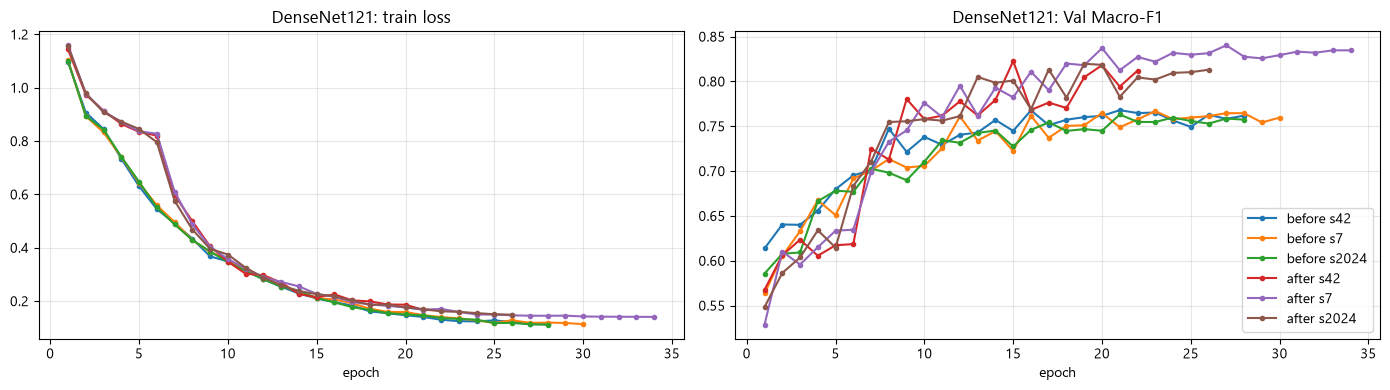


===== EfficientNet-B0: รอบที่ดีที่สุด = none =====
โหลด efficientnet_b0 seed 42 (before) จาก run e211fa47f4e3: Val Macro-F1 0.740
เทรน EfficientNet-B0 | before | seed 7 | run 10ed2ff1ef8e


  epoch  1 [head    ] loss 1.032 | val acc 0.586 F1 0.549  * | 72s


  epoch  2 [head    ] loss 0.825 | val acc 0.650 F1 0.634  * | 91s


  epoch  3 [head    ] loss 0.744 | val acc 0.660 F1 0.647  * | 108s


  epoch  4 [finetune] loss 0.645 | val acc 0.687 F1 0.665  * | 171s


  epoch  5 [finetune] loss 0.581 | val acc 0.684 F1 0.662 | 190s


... (382 outputs left out)

  epoch 33 [finetune] loss 0.156 | val acc 0.847 F1 0.827 | 794s


  epoch 34 [finetune] loss 0.154 | val acc 0.850 F1 0.829 | 820s


  epoch 35 [finetune] loss 0.152 | val acc 0.850 F1 0.829 | 846s


-> Val Macro-F1 0.830 | Acc 0.850 | 14.1 นาที


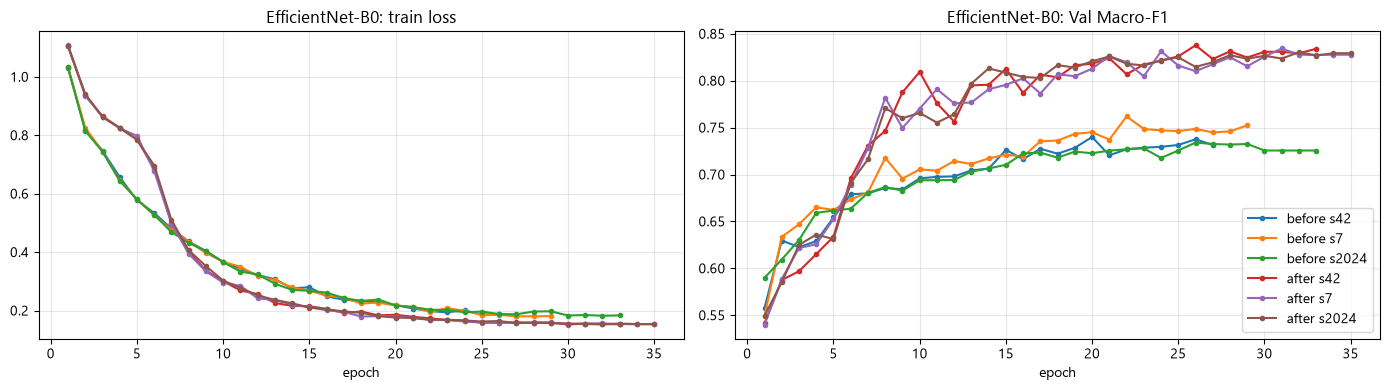

val_macro_f1        test_macro_f1       
                                mean    std          mean    std
model           variant                                         
DenseNet121     after          0.828  0.011         0.812  0.023
                before         0.766  0.003         0.693  0.001
EfficientNet-B0 after          0.834  0.004         0.833  0.002
                before         0.745  0.015         0.717  0.009

In [10]:
OTHERS = ["densenet121", "efficientnet_b0"]
OUT_DIR = RESULTS_DIR / "others"
OUT_DIR.mkdir(exist_ok=True)
screening = pd.read_csv(OUTPUT_DIR / "results" / "screening.csv")  # รอบคัดเลือกจาก notebook หลัก
storage = f"sqlite:///{(RESULTS_DIR / 'optuna.db').as_posix()}"
summary = []

for ARCH in OTHERS:
    sc = screening[screening.arch == ARCH]
    ROUND = sc.sort_values("val_macro_f1", ascending=False)["round"].iloc[0]
    BASE = {**DEFAULT_PARAMS, "aug": ROUND}
    name = fl.TV_ZOO[ARCH]["name"]
    print(f"\n===== {name}: รอบที่ดีที่สุด = {ROUND} =====")

    before = [train_one(ARCH, BASE, s, MAX_EPOCHS, "before") for s in SEEDS]

    study = optuna.create_study(study_name=f"other_{ARCH}_{ROUND}_ss2", storage=storage, direction="maximize",
                                load_if_exists=True,
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=4, n_warmup_steps=3))
    assert study.direction == optuna.study.StudyDirection.MAXIMIZE
    study.sampler = make_sampler(len(study.trials), SEED)

    def objective(trial):
        params = suggest_params(trial)
        try:
            rid = train_one(ARCH, params, SEED, TRIAL_EPOCHS, "trial", trial=trial)
        finally:
            import gc
            gc.collect()
            torch.cuda.empty_cache()
        trial.set_user_attr("run_id", rid)
        return load_run(rid)["val_metrics"]["macro_f1"]

    fail_stale_trials(study)
    n_left = remaining_trials(study, N_TRIALS)
    print(f"Optuna {name}: มี {len(study.trials)} trial แล้ว จะรันเพิ่ม {n_left}")
    if n_left:
        study.optimize(objective, n_trials=n_left, catch=(Exception,), gc_after_trial=True)
    tr = study.trials_dataframe(attrs=("number", "value", "state", "params", "duration", "user_attrs"))
    tr["duration_min"] = tr.pop("duration").dt.total_seconds() / 60
    tr.to_csv(OUT_DIR / f"optuna_trials_{ARCH}.csv", index=False)
    try:
        imp = optuna.importance.get_param_importances(study)
    except Exception as e:
        print("คำนวณ importance ไม่ได้:", e)
        imp = {}
    pd.DataFrame({"param": list(imp), "importance": list(imp.values())}).to_csv(
        OUT_DIR / f"optuna_importance_{ARCH}.csv", index=False)
    best = {**BASE, **study.best_params}
    print(f"trial ที่ดีที่สุด #{study.best_trial.number}: Val Macro-F1 {study.best_value:.3f}")

    after = [train_one(ARCH, best, s, MAX_EPOCHS, "after") for s in SEEDS]

    for v, rids in (("before", before), ("after", after)):
        for s, rid in zip(SEEDS, rids):
            va = load_run(rid)["val_metrics"]
            te = evaluate(y_te, predict_split(rid, "test"))
            summary.append({"model": name, "arch": ARCH, "round": ROUND, "variant": v, "seed": s, "run_id": rid,
                            "val_macro_f1": va["macro_f1"], "val_accuracy": va["accuracy"],
                            "test_accuracy": te["accuracy"], "test_macro_f1": te["macro_f1"],
                            "params": json.dumps(best if v == "after" else BASE)})
    pd.DataFrame(summary).to_csv(OUT_DIR / "before_after_others.csv", index=False)
    plot_history({f"before s{s}": r for s, r in zip(SEEDS, before)} | {f"after s{s}": r for s, r in zip(SEEDS, after)},
                 name, f"before_after_curves_{ARCH}.png")

res = pd.DataFrame(summary)
display(res.groupby(["model", "variant"])[["val_macro_f1", "test_macro_f1"]].agg(["mean", "std"]).round(3))